The goal of this notebook is to create warnings aka flags for our spatial predictions. 

Using thresholds for signal and shape metrics as derived from extensive EDA, we flag spatial predictions for certain cell types. 



In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import random
import math
import warnings 

import pandas as pd
import numpy as np
import zarr
from dotenv import dotenv_values
from matplotlib import pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.gridspec as gridspec

from hm3d_utils.utils import wrangle_dbscan
from hm3d_utils.spatial import BoundingBox3D

warnings.filterwarnings("ignore")

In [3]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

SPATIALDIR = DATADIR / "7_spatial"

OUTDIR = SPATIALDIR / "analyses"

SHAPE_FP = OUTDIR / "dbscan_metrics.csv"
SIGNAL_FP = OUTDIR / "high_confidence_cells.csv"

The thresholds were determined after extensive EDA.

In [4]:
MIN_NUM_CELLS_WARNING = 10

NUM_VOX_BIGGEST_MAX = 60_000

DBSCAN_CLUSTER_MAX_L2 = 200 
DBSCAN_CLUSTER_MAX_L3 = 100 
DBSCAN_CLUSTER_MAX_L4_L5 = 50

DBSCAN_REST_VOX_MAX_L2_L3 = 0.4
DBSCAN_REST_VOX_MAX_L4_L5 = 0.3

### Let's wrangle the input into a joined df

In [5]:
signal_df = pd.read_csv(SIGNAL_FP)
shape_df = pd.read_csv(SHAPE_FP)

# for all clusters and DBSCAN metrics, extract top 2 DBSCAN clusters, label the rest of them as "rest" 
dbscan_metrics = wrangle_dbscan(shape_df)
signal_df = signal_df.set_index("cluster")
joined = pd.concat([signal_df, dbscan_metrics], axis=1).reset_index().rename(columns = {
    "index": "cluster_label",
    "level": "clustering"
})

# one hot NN
joined["is_NN"] = 1
joined.loc[~joined.cluster_label.str.contains("NN"), "is_NN"] = 0
joined = joined.fillna(0)
joined["cluster_id"] = joined.cluster_label.apply(lambda x: x.split(" ")[0])

In [6]:
otsu_mapper = shape_df.drop_duplicates().set_index("cluster_name").to_dict()["otsu_thr"]
joined["otsu_thr"] = joined.cluster_label.map(otsu_mapper)

In [7]:
joined.head(2)

,cluster_label,clustering,n_cells_presmooth_p_gt_0.5,num_postsmooth_dbscan_clusters,num_vox_biggest_dbscan_cluster,percent_vox_biggest_dbscan_cluster,num_vox_second_biggest_dbscan_cluster,percent_vox_second_biggest_dbscan_cluster,num_vox_rest_dbscan_cluster,percent_vox_rest_dbscan_cluster,is_NN,cluster_id,otsu_thr
0,Gb1-2 GABA,L1,433607,23,655476,0.960278,13981.0,0.020482,13133.0,0.019240,0,Gb1-2,0.36083
1,Gl1-1 Glut,L1,256902,32,809906,0.994594,2793.0,0.003430,1609.0,0.001976,0,Gl1-1,0.21526


### Let's add the flags

Importantly, neuronal and non-neuronal cells are treated differently: Non-neuronal cells will not receive shape warnings as their shape in 3D is expected to be all over the place (consider astrocytes). 

In [8]:
joined["signal_warning"] = joined["n_cells_presmooth_p_gt_0.5"] < MIN_NUM_CELLS_WARNING 

joined["no_cells_warning"] = joined["n_cells_presmooth_p_gt_0.5"] == 0

joined["shape_warning"] = False

In [9]:
level = "L2"
is_NN = 0 

joined.loc[
    (joined.is_NN == is_NN) & 
    (joined.clustering == level) & 
    ((joined.num_postsmooth_dbscan_clusters > DBSCAN_CLUSTER_MAX_L2) | 
    (joined.percent_vox_rest_dbscan_cluster > DBSCAN_REST_VOX_MAX_L2_L3)),
    "shape_warning"
] = True

In [10]:
level = "L3"
is_NN = 0 

joined.loc[
    (joined.is_NN == is_NN) & 
    (joined.clustering == level) & 
    ((joined.num_postsmooth_dbscan_clusters > DBSCAN_CLUSTER_MAX_L3) | 
    (joined.percent_vox_rest_dbscan_cluster > DBSCAN_REST_VOX_MAX_L2_L3)),
    "shape_warning"
] = True

joined.loc[
        (joined.is_NN == is_NN) & 
        (joined.clustering == level) & 
        (joined.num_vox_biggest_dbscan_cluster > NUM_VOX_BIGGEST_MAX), 
        "shape_warning"
    ] = True

In [11]:
is_NN = 0 

for level in ["L4", "L5"]:

    joined.loc[
        (joined.is_NN == is_NN) & 
        (joined.clustering == level) & 
        ((joined.num_postsmooth_dbscan_clusters > DBSCAN_CLUSTER_MAX_L4_L5) | 
        (joined.percent_vox_rest_dbscan_cluster > DBSCAN_REST_VOX_MAX_L4_L5)),
        "shape_warning"
    ] = True

    joined.loc[
        (joined.is_NN == is_NN) & 
        (joined.clustering == level) & 
        (joined.num_vox_biggest_dbscan_cluster > NUM_VOX_BIGGEST_MAX), 
        "shape_warning"
    ] = True

In [12]:
joined["warning"] = "None" 
joined.loc[joined.shape_warning, "warning"] = "Shape"
joined.loc[joined.signal_warning, "warning"] = "Signal"
joined.loc[(joined.signal_warning) & (joined.shape_warning), "warning"] = "Signal and shape"
joined.loc[joined.no_cells_warning, "warning"] = "No cells"

In [13]:
joined.head(2)

,cluster_label,clustering,n_cells_presmooth_p_gt_0.5,num_postsmooth_dbscan_clusters,num_vox_biggest_dbscan_cluster,percent_vox_biggest_dbscan_cluster,num_vox_second_biggest_dbscan_cluster,percent_vox_second_biggest_dbscan_cluster,num_vox_rest_dbscan_cluster,percent_vox_rest_dbscan_cluster,is_NN,cluster_id,otsu_thr,signal_warning,no_cells_warning,shape_warning,warning
0,Gb1-2 GABA,L1,433607,23,655476,0.960278,13981.0,0.020482,13133.0,0.019240,0,Gb1-2,0.36083,False,False,False,None
1,Gl1-1 Glut,L1,256902,32,809906,0.994594,2793.0,0.003430,1609.0,0.001976,0,Gl1-1,0.21526,False,False,False,None


### Let's save

In [15]:
# whole data 
joined.to_csv(OUTDIR / "spatial_flags_metrics.csv", index=False)

In [16]:
# flags only 
joined.set_index("cluster_id").warning.to_csv(OUTDIR / "spatial_flags.csv")

### Let's plot the distribution of flags stratified per cell type

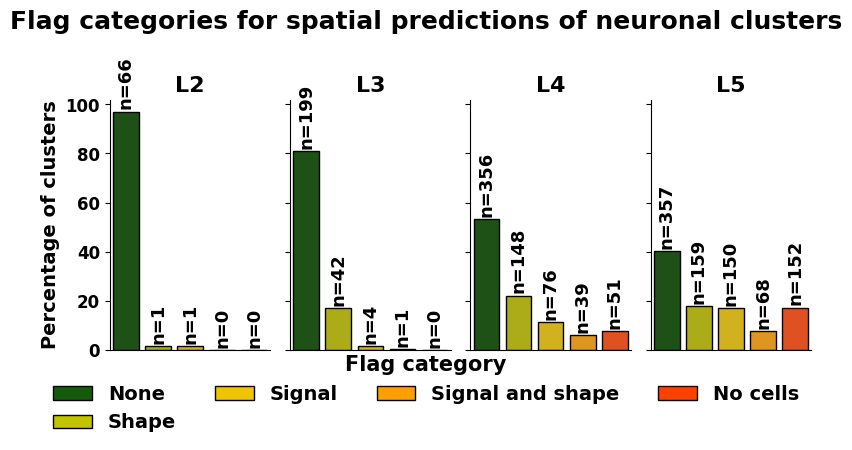

In [17]:

# --- SETTINGS ---
# Define warning order and color mapping
warning_order = ["None", "Shape", "Signal", "Signal and shape", "No cells",]
warning_colors = {
    "None": "#155b0c",
    "Shape": "#C3C400",
    "Signal": "#EFC400",
    "Signal and shape": "#FF9E00",
    "No cells": "#FF4100",
}

# --- DATA PREP ---
# Filter for is_NN == False and desired clustering levels
filtered = joined[
    (joined['is_NN'] == False) & 
    (joined['clustering'].isin(["L2", "L3", "L4", "L5"]))
].copy()

# Ensure 'warning' is a categorical column with defined order
filtered['warning'] = pd.Categorical(filtered['warning'], categories=warning_order, ordered=True)

# Compute count and percentage per clustering and warning
percentage_df = (
    filtered.groupby(['clustering', 'warning'])
    .size()
    .reset_index(name='count')
)

# Compute total rows per clustering group for percentage calculation
totals = percentage_df.groupby('clustering')['count'].transform('sum')
percentage_df['percentage'] = (percentage_df['count'] / totals) * 100

# --- PLOTTING ---
# Create a FacetGrid for the 4 clustering levels
g = sns.FacetGrid(
    data=percentage_df,
    col='clustering',
    col_order=['L2', 'L3', 'L4', 'L5'],
    sharey=True,
    height=5,
    aspect=0.4
)

# Plot the bar plots
g.map_dataframe(
    sns.barplot,
    x='warning',
    y='percentage',
    order=warning_order,
    palette=warning_colors,
    edgecolor='black'
)

# Annotate and style each subplot
for ax, (clustering_level, group_df) in zip(g.axes.flat, percentage_df.groupby('clustering')):
    # Add count annotations
    for warning in warning_order:
        row = group_df[group_df['warning'] == warning]
        if not row.empty:
            y_val = row['percentage'].values[0]
            count = int(row['count'].values[0])
            ax.text(
                x=warning_order.index(warning),
                y=y_val + 1,
                s=f"n={count}",
                ha='center',
                va='bottom',
                fontsize=13,
                fontweight='bold',
                rotation=90
            )

    # Clean up x-axis and y-axis
    ax.set_xlabel('')
    ax.set_xticks([])
    ax.set_ylabel('Percentage of clusters', fontsize=14, fontweight='bold')
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(f"{clustering_level}", fontsize=16, fontweight='bold')
    
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')

    sns.despine(ax=ax)

# Remove x-axis label globally
g.set_axis_labels("", "Percentage of clusters")

# --- SUPER TITLE ---
g.fig.suptitle(
    "Flag categories for spatial predictions of neuronal clusters",
    fontsize=18,
    fontweight='bold'
)

# Adjust layout to make room for legend and title
plt.tight_layout()
plt.subplots_adjust(top=0.8, bottom=0.3)

# --- LEGEND ---
# Create custom legend handles
legend_elements = [
    Patch(facecolor=warning_colors[label], edgecolor='black', label=label)
    for label in warning_order
]

# Add legend to the figure (centered below all subplots)
legend = g.fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=4,
    frameon=False,
    title='Flag category',
    fontsize=14,
    title_fontsize=15,
    bbox_to_anchor=(0.5, 0.1)
)

# Make legend title and text bold
for text in legend.get_texts():
    text.set_fontweight('bold')
legend.get_title().set_fontweight('bold')

# --- OPTIONAL: Save to file ---
g.fig.savefig(OUTDIR / "warning_categories_by_clustering_N.pdf", dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


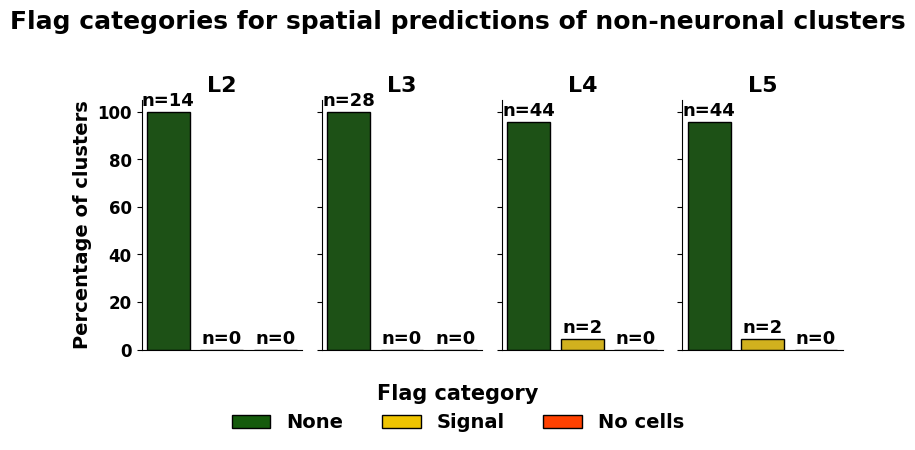

In [18]:

# --- SETTINGS ---
# Define warning order and color mapping
warning_order = ["None", #"Shape", 
"Signal", "No cells", 
]
warning_colors = {
    "None": "#155b0c",
    "Shape": "#C3C400",
    "Signal": "#EFC400",
    "Signal and shape": "#FF9E00",
    "No cells": "#FF4100",
}

# --- DATA PREP ---
# Filter for is_NN == False and desired clustering levels
filtered = joined[
    (joined['is_NN'] == True) & 
    (joined['clustering'].isin(["L2", "L3", "L4", "L5"]))
].copy()

# Ensure 'warning' is a categorical column with defined order
filtered['warning'] = pd.Categorical(filtered['warning'], categories=warning_order, ordered=True)

# Compute count and percentage per clustering and warning
percentage_df = (
    filtered.groupby(['clustering', 'warning'])
    .size()
    .reset_index(name='count')
)

# Compute total rows per clustering group for percentage calculation
totals = percentage_df.groupby('clustering')['count'].transform('sum')
percentage_df['percentage'] = (percentage_df['count'] / totals) * 100

# --- PLOTTING ---
# Create a FacetGrid for the 4 clustering levels
g = sns.FacetGrid(
    data=percentage_df,
    col='clustering',
    col_order=['L2', 'L3', 'L4', 'L5'],
    sharey=True,
    height=5,
    aspect=0.4
)

# Plot the bar plots
g.map_dataframe(
    sns.barplot,
    x='warning',
    y='percentage',
    order=warning_order,
    palette=warning_colors,
    edgecolor='black'
)

# Annotate and style each subplot
for ax, (clustering_level, group_df) in zip(g.axes.flat, percentage_df.groupby('clustering')):
    # Add count annotations
    for warning in warning_order:
        row = group_df[group_df['warning'] == warning]
        if not row.empty:
            y_val = row['percentage'].values[0]
            count = int(row['count'].values[0])
            ax.text(
                x=warning_order.index(warning),
                y=y_val + 1,
                s=f"n={count}",
                ha='center',
                va='bottom',
                fontsize=13,
                fontweight='bold',
                #rotation=90
            )

    # Clean up x-axis and y-axis
    ax.set_xlabel('')
    ax.set_xticks([])
    ax.set_ylabel('Percentage of clusters', fontsize=14, fontweight='bold')
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(f"{clustering_level}", fontsize=16, fontweight='bold')
    
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')

    sns.despine(ax=ax)

# Remove x-axis label globally
g.set_axis_labels("", "Percentage of clusters")

# --- SUPER TITLE ---
g.fig.suptitle(
    "Flag categories for spatial predictions of non-neuronal clusters",
    fontsize=18,
    fontweight='bold'
)

# Adjust layout to make room for legend and title
plt.tight_layout()
plt.subplots_adjust(top=0.8, bottom=0.3)

# --- LEGEND ---
# Create custom legend handles
legend_elements = [
    Patch(facecolor=warning_colors[label], edgecolor='black', label=label)
    for label in warning_order
]

# Add legend to the figure (centered below all subplots)
legend = g.fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=3,
    frameon=False,
    title='Flag category',
    fontsize=14,
    title_fontsize=15,
    bbox_to_anchor=(0.5, 0.1)
)

# Make legend title and text bold
for text in legend.get_texts():
    text.set_fontweight('bold')
legend.get_title().set_fontweight('bold')

# --- OPTIONAL: Save to file ---
g.fig.savefig(OUTDIR / "warning_categories_by_clustering_NN.pdf", dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


## Plotting/EDA (cave: preliminary labels)

In [ ]:
# Load voxel grid Zarr store
voxel_store = zarr.open(SPATIALDIR / 'sp_voxels.zarr')
voxel_store.tree()

/
├── L1_mass (6, 168, 144, 107) float32
├── L1_prob (6, 168, 144, 107) float32
├── L1_rel_mass (6, 168, 144, 107) float32
├── L2_mass (82, 168, 144, 107) float32
├── L2_prob (82, 168, 144, 107) float32
├── L2_rel_mass (82, 168, 144, 107) float32
├── L3_mass (274, 168, 144, 107) float32
├── L3_prob (274, 168, 144, 107) float32
├── L3_rel_mass (274, 168, 144, 107) float32
├── L4_mass (716, 168, 144, 107) float32
├── L4_prob (716, 168, 144, 107) float32
├── L4_rel_mass (716, 168, 144, 107) float32
├── L5_mass (932, 168, 144, 107) float32
├── L5_prob (932, 168, 144, 107) float32
├── L5_rel_mass (932, 168, 144, 107) float32
├── counts (168, 144, 107) float32
├── evidence (168, 144, 107) float32
├── latent_embedding (45, 168, 144, 107) float32
├── region_labels (168, 144, 107) uint32
└── region_masks (176, 168, 144, 107) bool

In [ ]:
bbox = BoundingBox3D.load(SPATIALDIR / "bounding_box_ccf_mm.json")
bbox

Bounding Box Ranges (CCFv3 mm):
 x: 4.375<->8.55
 y: 3.95<->7.525
 z: 3.05<->5.7

In [ ]:
xx = np.arange(start=bbox.min[0], stop=bbox.max[0], step=0.025) 
yy = np.arange(start=bbox.min[1], stop=bbox.max[1]+0.025, step=0.025) 
zz = np.arange(start=bbox.min[2], stop=bbox.max[2], step=0.025) 

len(xx), len(yy), len(zz)

(168, 144, 107)

In [ ]:
# Create 3D meshgrid from coordinate arrays
X, Y, Z = np.meshgrid(xx, yy, zz, indexing='ij')

# Stack into a single array of shape (nx, ny, nz, 3)
grid = np.stack([X, Y, Z], axis=-1)

coords = grid.reshape(-1, 3)

In [ ]:
coords

array([[4.375, 3.95 , 3.05 ],
       [4.375, 3.95 , 3.075],
       [4.375, 3.95 , 3.1  ],
       ...,
       [8.55 , 7.525, 5.65 ],
       [8.55 , 7.525, 5.675],
       [8.55 , 7.525, 5.7  ]], shape=(2588544, 3))

In [ ]:
def _get_probs_flat(cluster_label):
    lvl = cluster_label[2]
    # get idx of cluster 
    i = voxel_store[f"L{lvl}_rel_mass"].attrs["labels"].index(cluster_label)
    # get probs and flatten
    probs = voxel_store[f"L{lvl}_prob"][i, :, :, :].reshape(-1)
    probs = np.nan_to_num(probs, nan=0.0)
    return probs
    
def plot_clusters_by_bins_3d(
    joined,
    level,
    is_NN,
    signal_min,
    bin_col,
    k=4,
    n=4,
    start_bin=0,
    figsize=(12, 10),
    seed=42
):
    """
    Plot 3D voxel clusters from k evenly spaced bins based on a selected column in `joined`.

    Parameters:
        joined : pd.DataFrame
            Cluster-level metadata with DBSCAN and other statistics
        level : str
            Clustering level to filter by (joined.clustering == level)
        is_NN : bool
            Whether to filter for NN clustering (joined.is_NN == is_NN)
        signal_min : float
            Minimum value for `log_n_cells_presmooth_p_gt_0.5` to include cluster
        bin_col : str
            Column in `joined` to use for binning
        k : int
            Number of evenly spaced bins to divide the data
        n : int
            Number of random clusters to sample and plot per bin
        start_bin : int
            Index of the first bin to plot (bins before this index are skipped)
        figsize : tuple
            Base figure size
        seed : int
            Random seed
    """

    # Step 1: Filter joined
    filtered = joined[
        (joined["clustering"] == level) &
        (joined["is_NN"] == is_NN) &
        (joined["n_cells_presmooth_p_gt_0.5"] > signal_min)
    ].copy()

    if filtered.empty:
        print("No data after filtering. Check your parameters.")
        return

    # Step 2: Create k evenly spaced bins from min to max of the selected column
    min_val = filtered[bin_col].min()
    max_val = filtered[bin_col].max()
    bin_edges = np.linspace(min_val, max_val, k + 1)

    filtered["bin"] = pd.cut(filtered[bin_col], bins=bin_edges, labels=False, include_lowest=True)

    # Step 3: Plot clusters per bin (starting from start_bin)
    for bin_idx in sorted(filtered["bin"].dropna().unique()):
        if bin_idx < start_bin:
            continue  # skip bins before start_bin

        bin_df = filtered[filtered["bin"] == bin_idx]
        cluster_labels = bin_df["cluster_label"].unique()

        if len(cluster_labels) == 0:
            print(f"No clusters in bin {bin_idx}")
            continue

        if len(cluster_labels) < n:
            print(f"Bin {bin_idx} has only {len(cluster_labels)} clusters; plotting all.")
            sampled_labels = cluster_labels
        else:
            random.seed(seed)
            sampled_labels = random.sample(list(cluster_labels), n)

        # Dynamic subplot layout
        cols = 2 if len(sampled_labels) > 1 else 1
        rows = math.ceil(len(sampled_labels) / cols)
        fig_local = plt.figure(figsize=(figsize[0], rows * 5))

        for i, cluster_label in enumerate(sampled_labels):
            cluster_data = bin_df[bin_df["cluster_label"] == cluster_label]
            if cluster_data.empty:
                continue

            otsu_val = cluster_data["otsu_thr"].values[0]
            n_cells_low = cluster_data["n_cells_presmooth_p_gt_0.5"].values[0]
            num_dbscan = cluster_data["num_postsmooth_dbscan_clusters"].values[0]
            percent_vox_rest = cluster_data["percent_vox_rest_dbscan_cluster"].values[0]
            num_vox_big = cluster_data["num_vox_biggest_dbscan_cluster"].values[0]

            prob = _get_probs_flat(cluster_label)
            mask = prob >= otsu_val

            if not mask.any():
                print(f"No voxels above threshold for {cluster_label}")
                continue

            x = - coords[mask, 2] # - z
            y = coords[mask, 0] # x
            z = - coords[mask, 1] # -y 

            ax = fig_local.add_subplot(rows, cols, i + 1, projection='3d')
            ax.scatter(x, y, z, s=1, alpha=0.6)

            ax.set_title(
                f"Bin {bin_idx} - {cluster_label}\n"
                f"Cells: {int(n_cells_low)} | Otsu: {otsu_val:.5f}\n"
                f"Clusters: {num_dbscan} | Rest: {percent_vox_rest*100:.1f}% | Biggest: {num_vox_big}",
                fontsize=9
            )
            ax.set_xlabel("z")
            ax.set_ylabel("x")
            ax.set_zlabel("y")
            ax.set_ylim(4, 8)
            ax.set_xlim(-6, -2)
            ax.set_zlim(-8, -4)

        fig_local.suptitle(f"Bin {bin_idx} by '{bin_col}' [{bin_edges[bin_idx]:.2f} - {bin_edges[bin_idx+1]:.2f}]", fontsize=14)
        fig_local.tight_layout(rect=[0, 0, 1, 0.97])
        plt.show()


def plot_random_clusters_by_warning_qc_3d(
    joined,
    level,
    is_NN,
    n=3,
    figsize=(8, 6),
    use_frontleft=False,
    random_state=None,
    single_plots=False,
):
    """
    Randomly sample and plot 3D voxel clusters per warning category.

    Parameters:
        joined : pd.DataFrame
            Cluster-level metadata (with warning categories and CCF coordinates)
        level : str
            Clustering level to filter by
        is_NN : bool
            Whether to filter by is_NN column
        n : int
            Number of random clusters to sample per warning category
        figsize : tuple
            Size of each individual 3D plot (if single_plots=True), or size of each subplot
        use_frontleft : bool
            Whether to swap axis order for front-left view
        random_state : int or None
            Seed for reproducibility
        single_plots : bool
            If True, create individual plots per cluster. If False, create one figure per warning category with subplots.
    """
    rng = np.random.default_rng(random_state)

    for warning_category in joined["warning"].dropna().unique():
        if warning_category == "No pred":
            continue 
        else:
            subset = joined[
                (joined["clustering"] == level) &
                (joined["is_NN"] == is_NN) &
                (joined["warning"] == warning_category)
            ]

            if subset.empty:
                print(f"No clusters found for warning category: {warning_category}")
                continue

            sampled = subset.sample(n=min(n, len(subset)), random_state=random_state).reset_index(drop=True)

            if single_plots:
                # One plot per cluster (current behavior)
                for _, cluster_data in sampled.iterrows():
                    cluster_label = cluster_data["cluster_label"]
                    _plot_single_cluster(
                        cluster_label, cluster_data, warning_category,
                        figsize, use_frontleft
                    )
            else:
                # One plot per warning category with subplots
                num_clusters = len(sampled)
                num_cols = 2
                num_rows = math.ceil(num_clusters / num_cols)
                fig = plt.figure(figsize=(figsize[0] * num_cols, figsize[1] * num_rows))
                gs = gridspec.GridSpec(num_rows, num_cols, figure=fig)
                fig.suptitle(f"Warning: {warning_category}", fontsize=30)

                for i, cluster_data in sampled.iterrows():
                    cluster_label = cluster_data["cluster_label"]

                    # Mask
                    prob = _get_probs_flat(cluster_label)
                    mask = prob >= cluster_data["otsu_thr"]
                    if not mask.any():
                        print(f"No voxels above Otsu threshold for {cluster_label}")
                        continue

                    # Coordinates
                    if use_frontleft:
                        x = coords[mask, 0] # x
                        y = - coords[mask, 2] # - z
                    else:
                        x = - coords[mask, 2] # - z
                        y = coords[mask, 0] # x
                    z = - coords[mask, 1] # -y 

                    row, col = divmod(i, num_cols)
                    ax = fig.add_subplot(gs[row, col], projection='3d')
                    ax.scatter(x, y, z, s=1, alpha=0.6)

                    # Title
                    ax.set_title(
                        f"{cluster_label}\n"
                        f"Cells: {int(cluster_data['n_cells_presmooth_p_gt_0.5'])} | Otsu: {cluster_data['otsu_thr']:.5f}\n"
                        f"Clusters: {cluster_data['num_postsmooth_dbscan_clusters']} | "
                        f"Rest: {cluster_data['percent_vox_rest_dbscan_cluster']*100:.1f}% | "
                        f"Biggest: {cluster_data['num_vox_biggest_dbscan_cluster']} | "
                        f"% 2nd: {cluster_data['percent_vox_second_biggest_dbscan_cluster']:.2f}",
                        fontsize=15
                    )

                    # Axis labels
                    if use_frontleft:
                        ax.set_xlabel("x")
                        ax.set_ylabel("z")
                    else:
                        ax.set_xlabel("z")
                        ax.set_ylabel("x")
                    ax.set_zlabel("y")

                    # Limits
                    if use_frontleft:
                        ax.set_ylim(-2, -6)
                        ax.set_xlim(8, 4)
                    else:
                        ax.set_ylim(4, 8)
                        ax.set_xlim(-6, -2)
                    ax.set_zlim(-8, -4)

                plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle
                plt.show()


def _plot_single_cluster(cluster_label, cluster_data, warning_category, figsize, use_frontleft):
    """
    Helper function to plot a single cluster in its own 3D plot.
    """

    prob = _get_probs_flat(cluster_label)
    mask = prob >= cluster_data["otsu_thr"]

    if not mask.any():
        print(f"No voxels above Otsu threshold for {cluster_label}")
        return

    if use_frontleft:
        x = coords[mask, 0] # x
        y = - coords[mask, 2] # - z
    else:
        x = - coords[mask, 2] # - z
        y = coords[mask, 0] # x
    z = - coords[mask, 1] # -y 

    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(x, y, z, s=1, alpha=0.6)

    ax.set_title(
        f"[{warning_category}] — {cluster_label}\n"
        f"Cells: {int(cluster_data['n_cells_presmooth_p_gt_0.5'])} | Otsu: {cluster_data['otsu_thr']:.5f}\n"
        f"Clusters: {cluster_data['num_postsmooth_dbscan_clusters']} | "
        f"Rest: {cluster_data['percent_vox_rest_dbscan_cluster']*100:.1f}% | "
        f"Biggest: {cluster_data['num_vox_biggest_dbscan_cluster']} | "
        f"% 2nd: {cluster_data['percent_vox_second_biggest_dbscan_cluster']:.2f}",
        fontsize=10
    )

    if use_frontleft:
        ax.set_xlabel("x")
        ax.set_ylabel("z")
        ax.set_ylim(-2, -6)
        ax.set_xlim(8, 4)
    else:
        ax.set_xlabel("z")
        ax.set_ylabel("x")
        ax.set_ylim(4, 8)
        ax.set_xlim(-6, -2)
    ax.set_zlabel("y")
    ax.set_zlim(-8, -4)

    plt.tight_layout()
    plt.show()


### Plotting random clusters across bins of metric

You can use the next cell to plot random clusters sampled from evenly-spaced bins of a metric. 

This was used heavily during EDA as to get sensible thresholds.

What is being plotted are the foreground voxels for each of the clusters picked; i.e., the voxels whose p is greater than the otsu threshold used for binarization.

In [ ]:
# signal_min = 10 # only plot clusters with at least this number of cells

# level = "L3"

# is_NN = 0

# choose a metric
# #bin_col = "percent_vox_rest_dbscan_cluster"
# #bin_col = "num_postsmooth_dbscan_clusters"
# bin_col = "num_vox_biggest_dbscan_cluster"

# plot_clusters_by_bins_3d(
#     joined,
#     level,
#     is_NN,
#     signal_min,
#     bin_col = bin_col,
#     k=10,
#     n=8,
#     start_bin=0,
#     figsize=(12, 10),
#     seed=42
# )

### Plotting random clusters from each warning category

Note: use use_frontleft=False in the next function to get the same perspective onto the HY as in the function above.

In the below plots, anterior HY points right; lateral HY points towards the viewer; the Y axis is the midline of the brain.

As above, what is being plotted are the foreground voxels for each of the clusters picked; i.e., the voxels whose p is greater than the otsu threshold used for binarization which will show the spatial "hotspots" of a cell type.

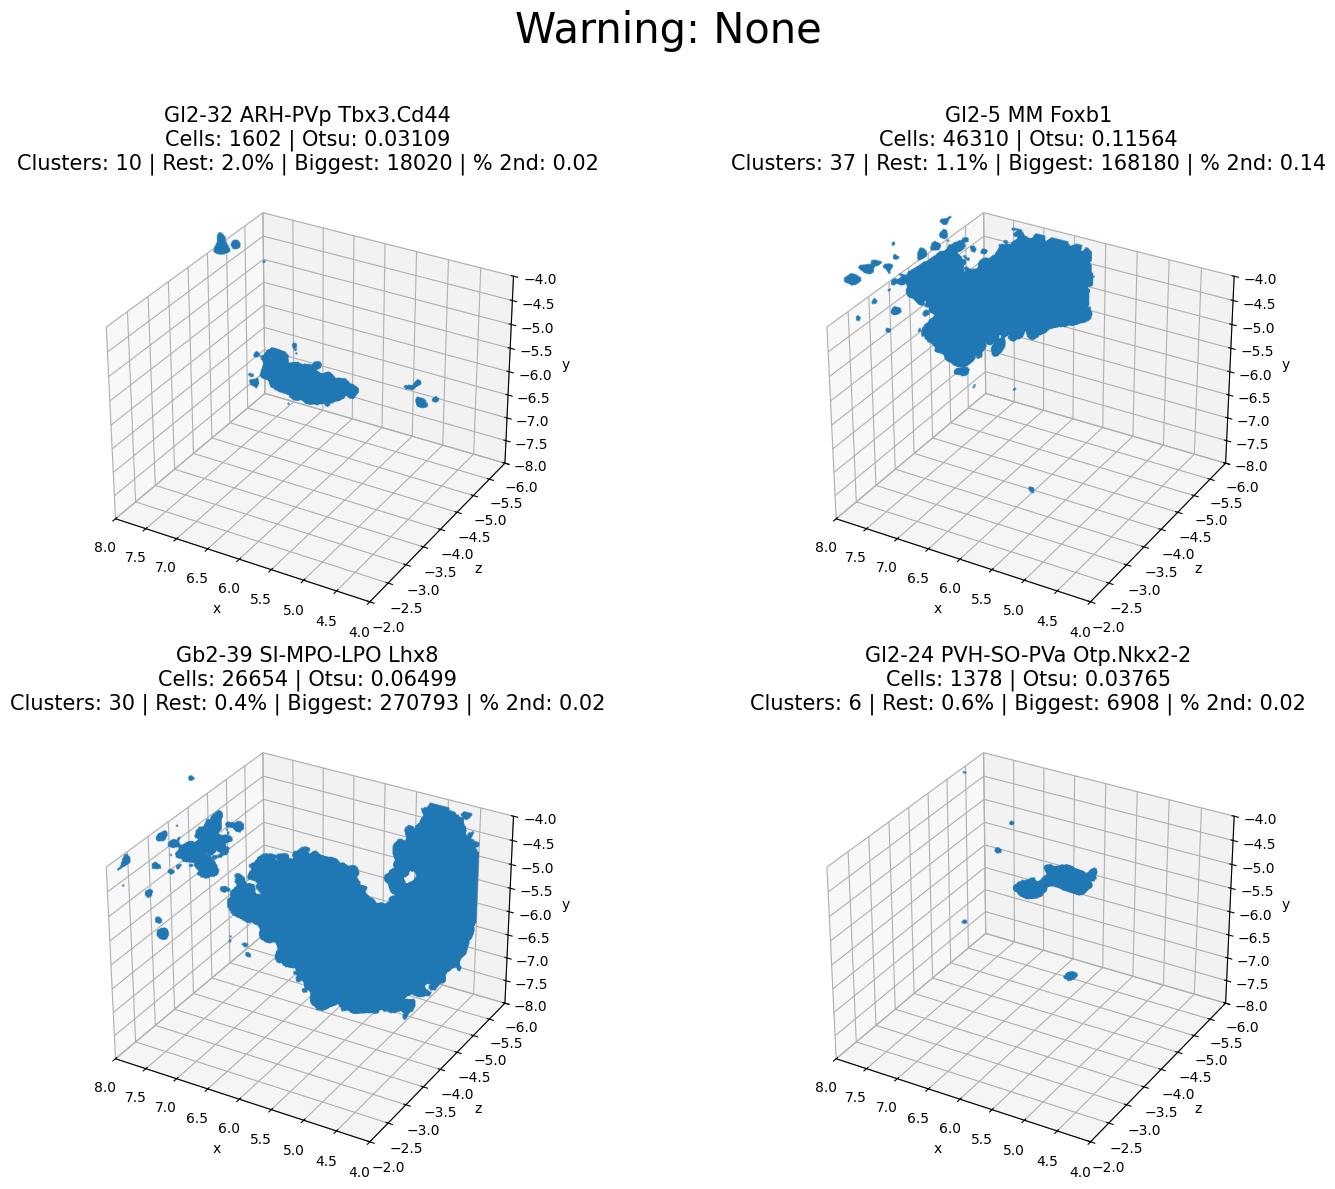

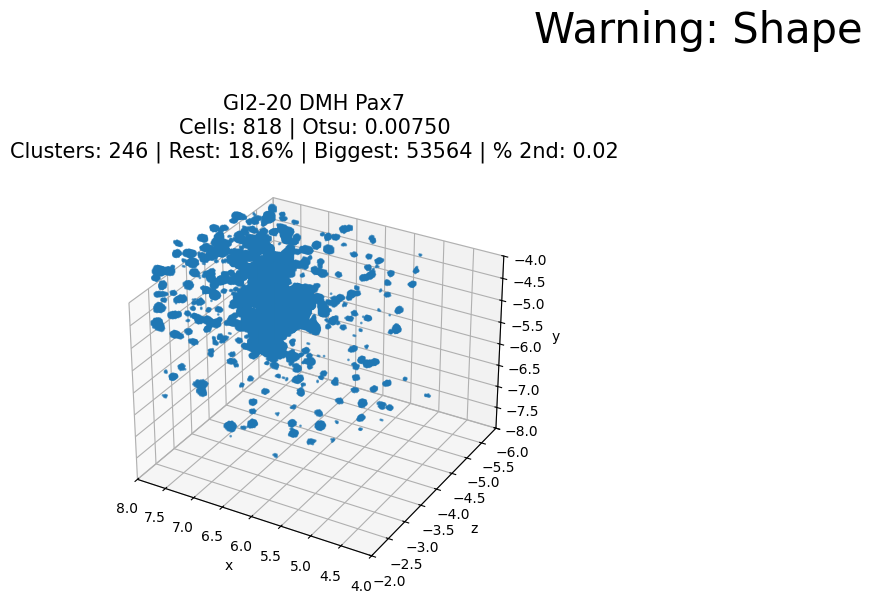

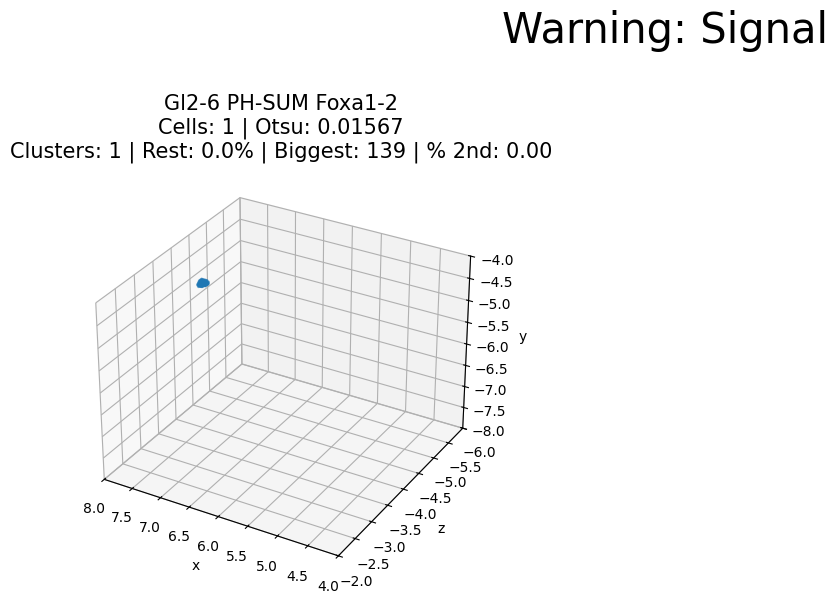

No clusters found for warning category: Signal and shape
No clusters found for warning category: No cells


In [ ]:
lvl= "L2"

plot_random_clusters_by_warning_qc_3d(
    joined=joined,
    level=lvl,
    is_NN=False,
    n=4,
    random_state=42,
    use_frontleft = True,
    single_plots=False
)

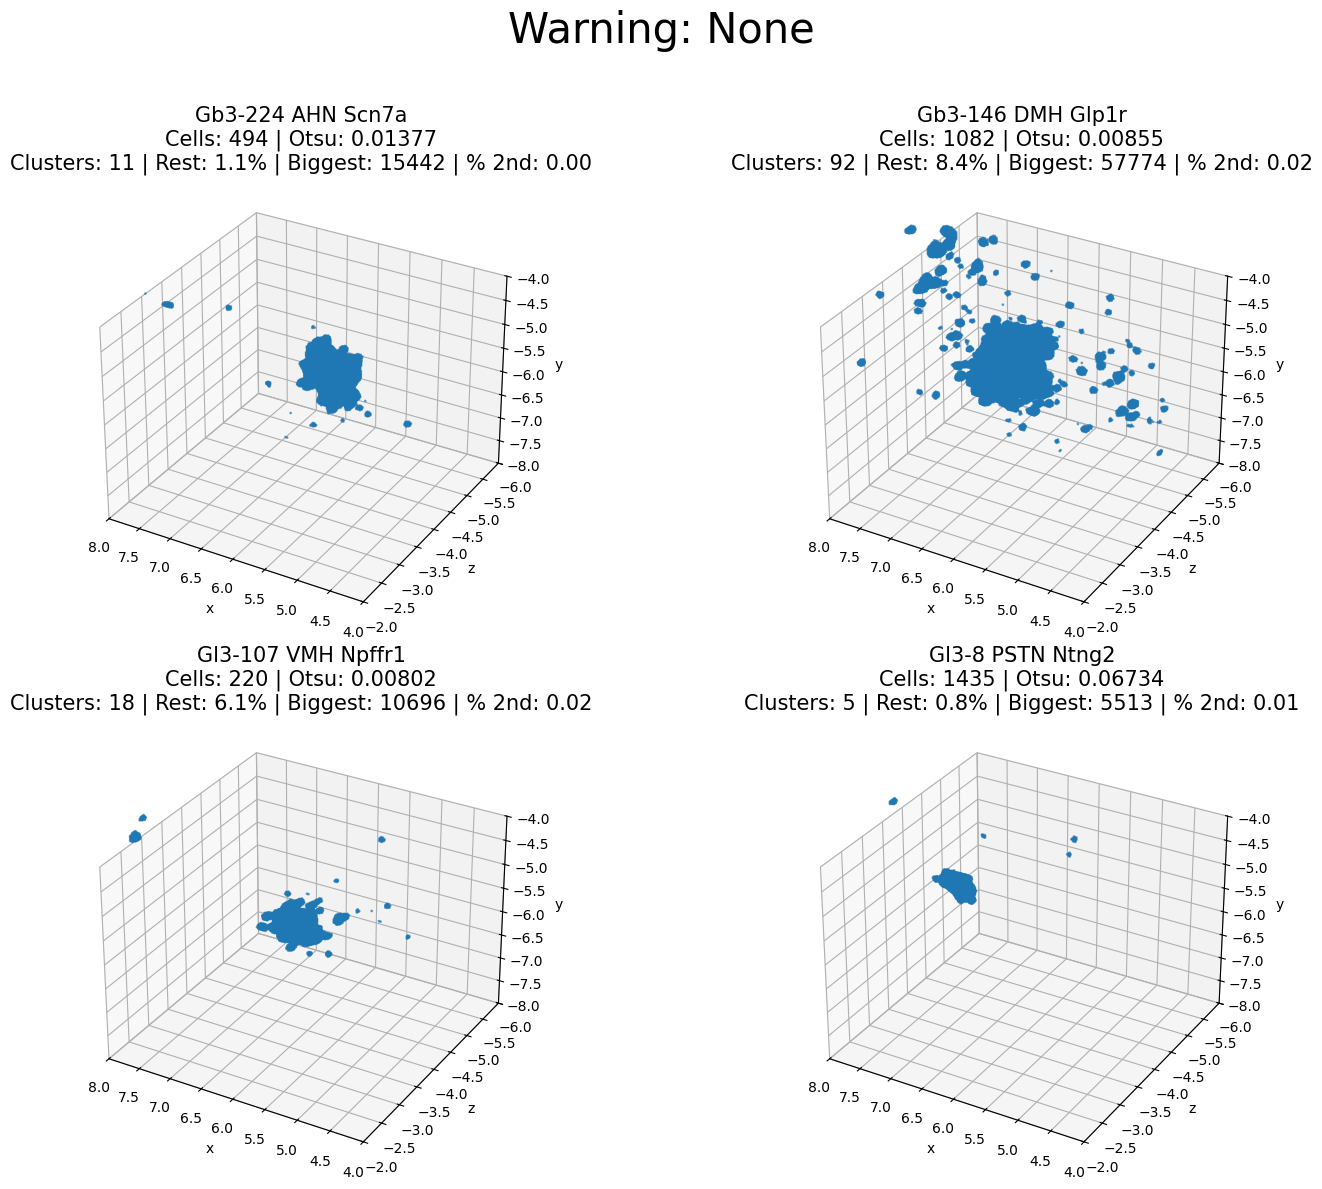

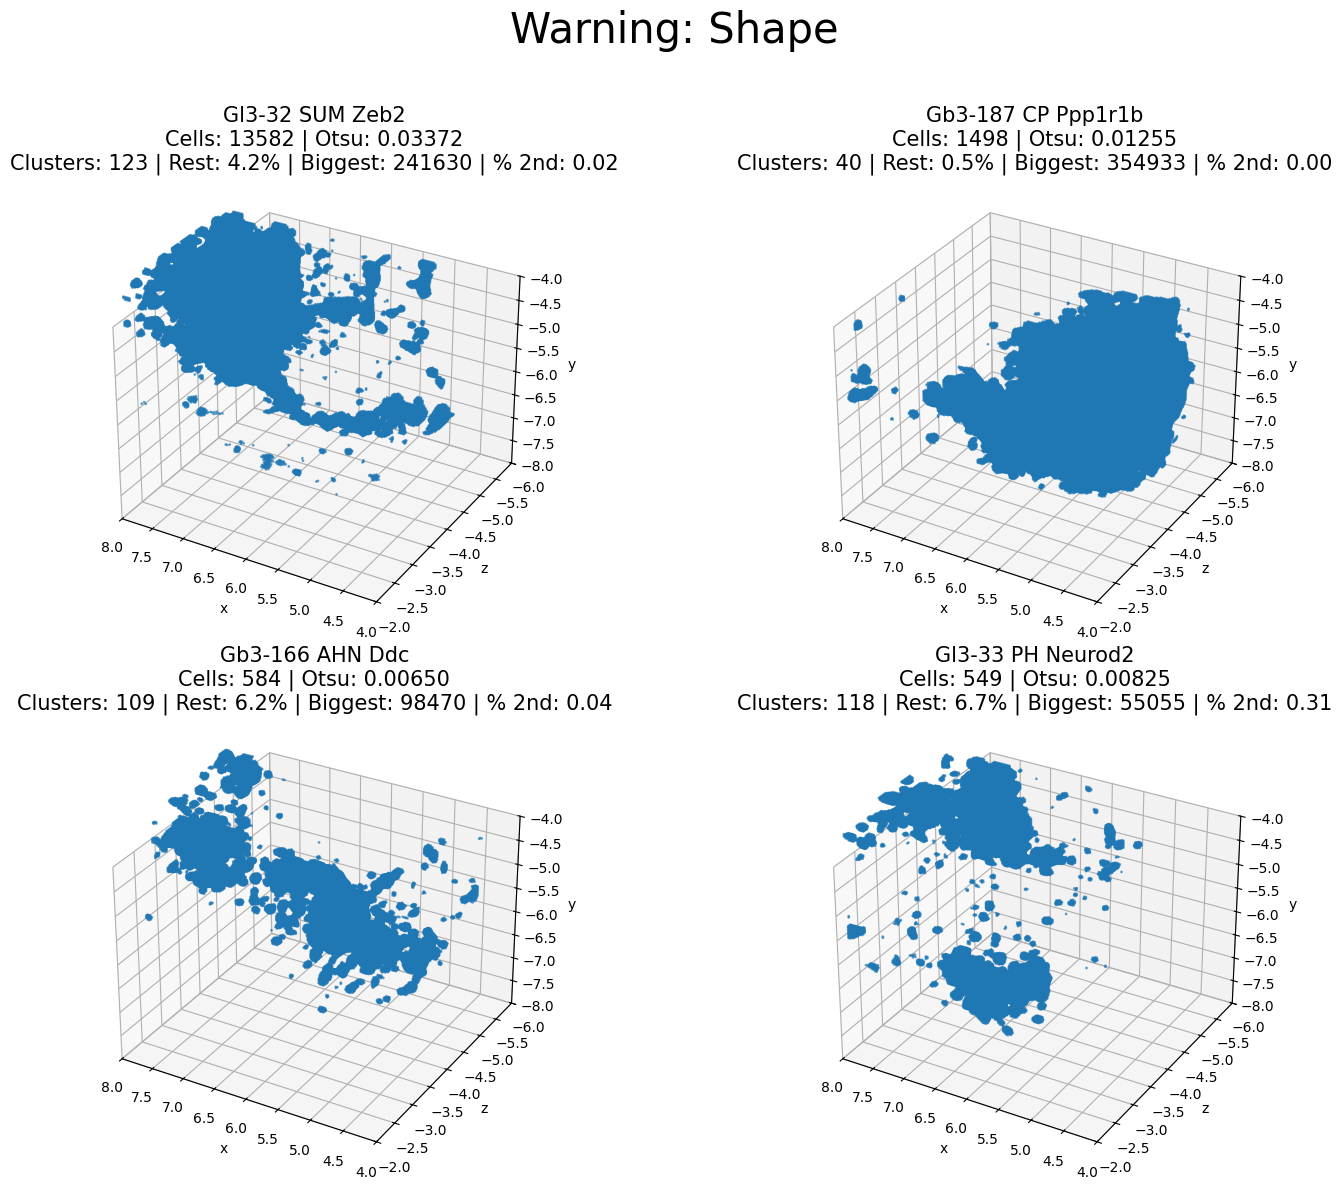

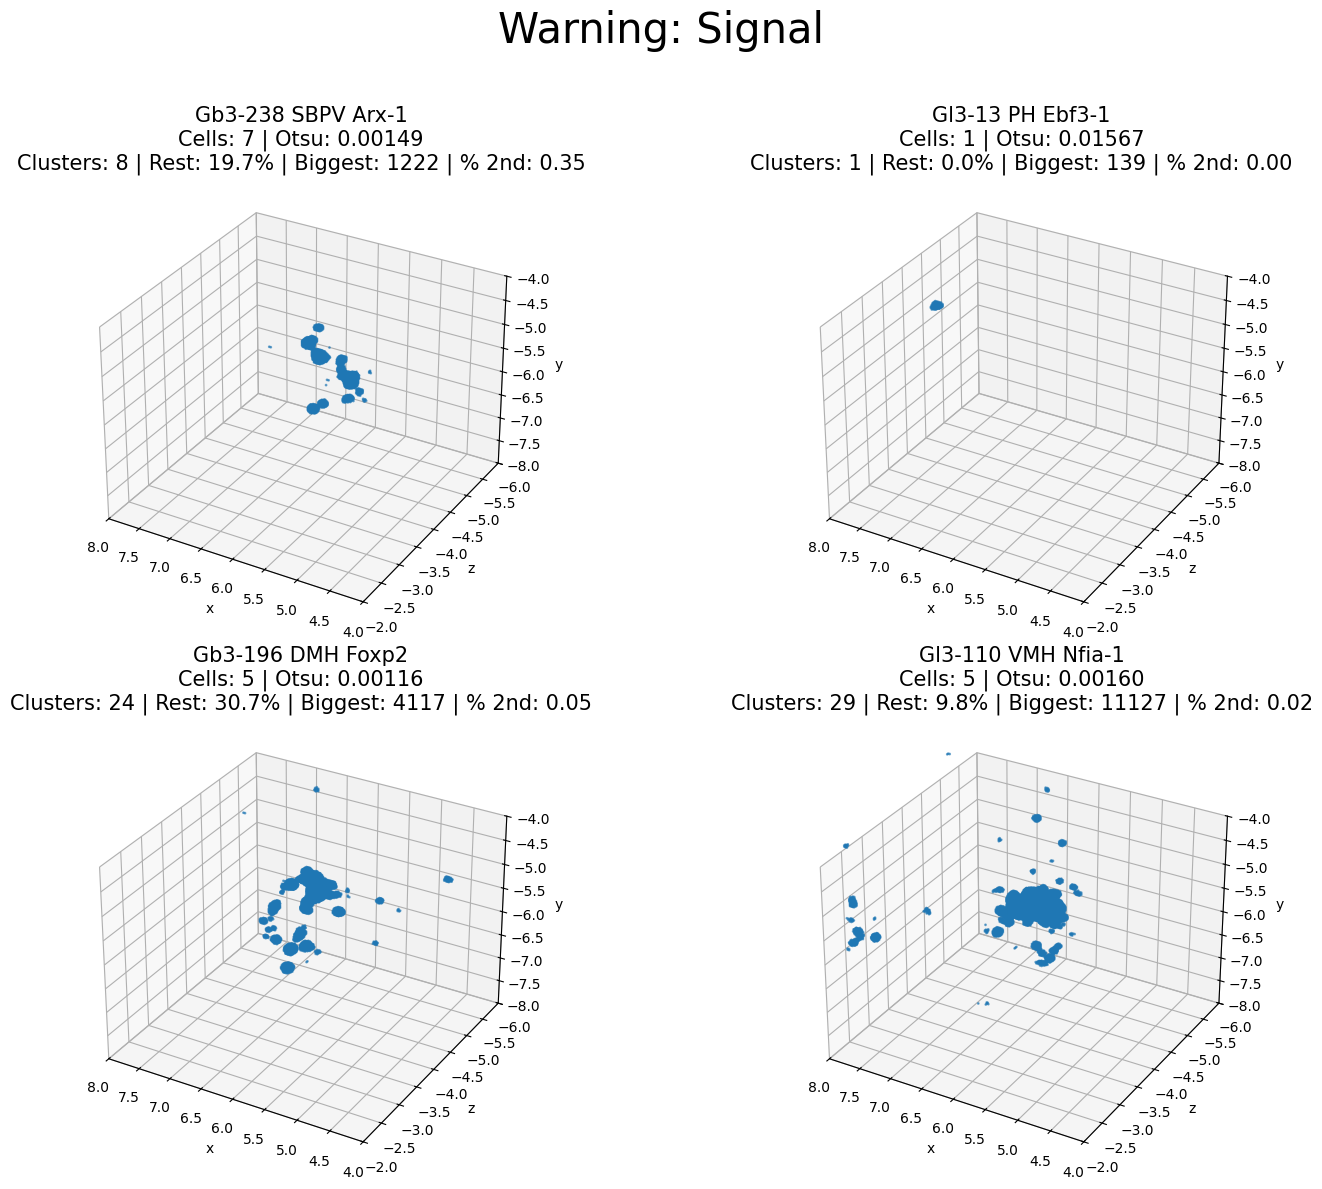

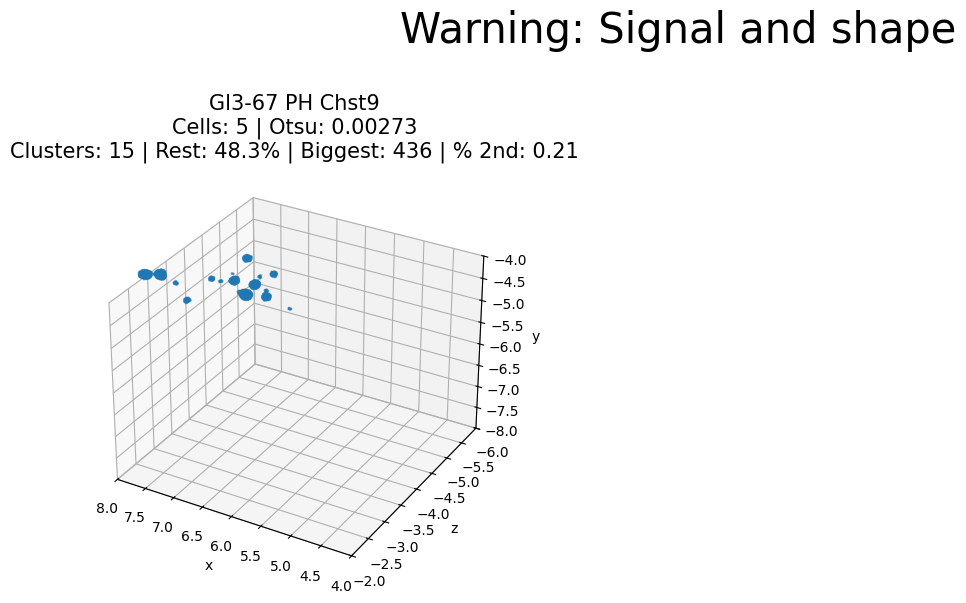

No clusters found for warning category: No cells


In [ ]:
lvl= "L3"

plot_random_clusters_by_warning_qc_3d(
    joined=joined,
    level=lvl,
    is_NN=False,
    n=4,
    random_state=42,
    use_frontleft = True,
    single_plots=False
)

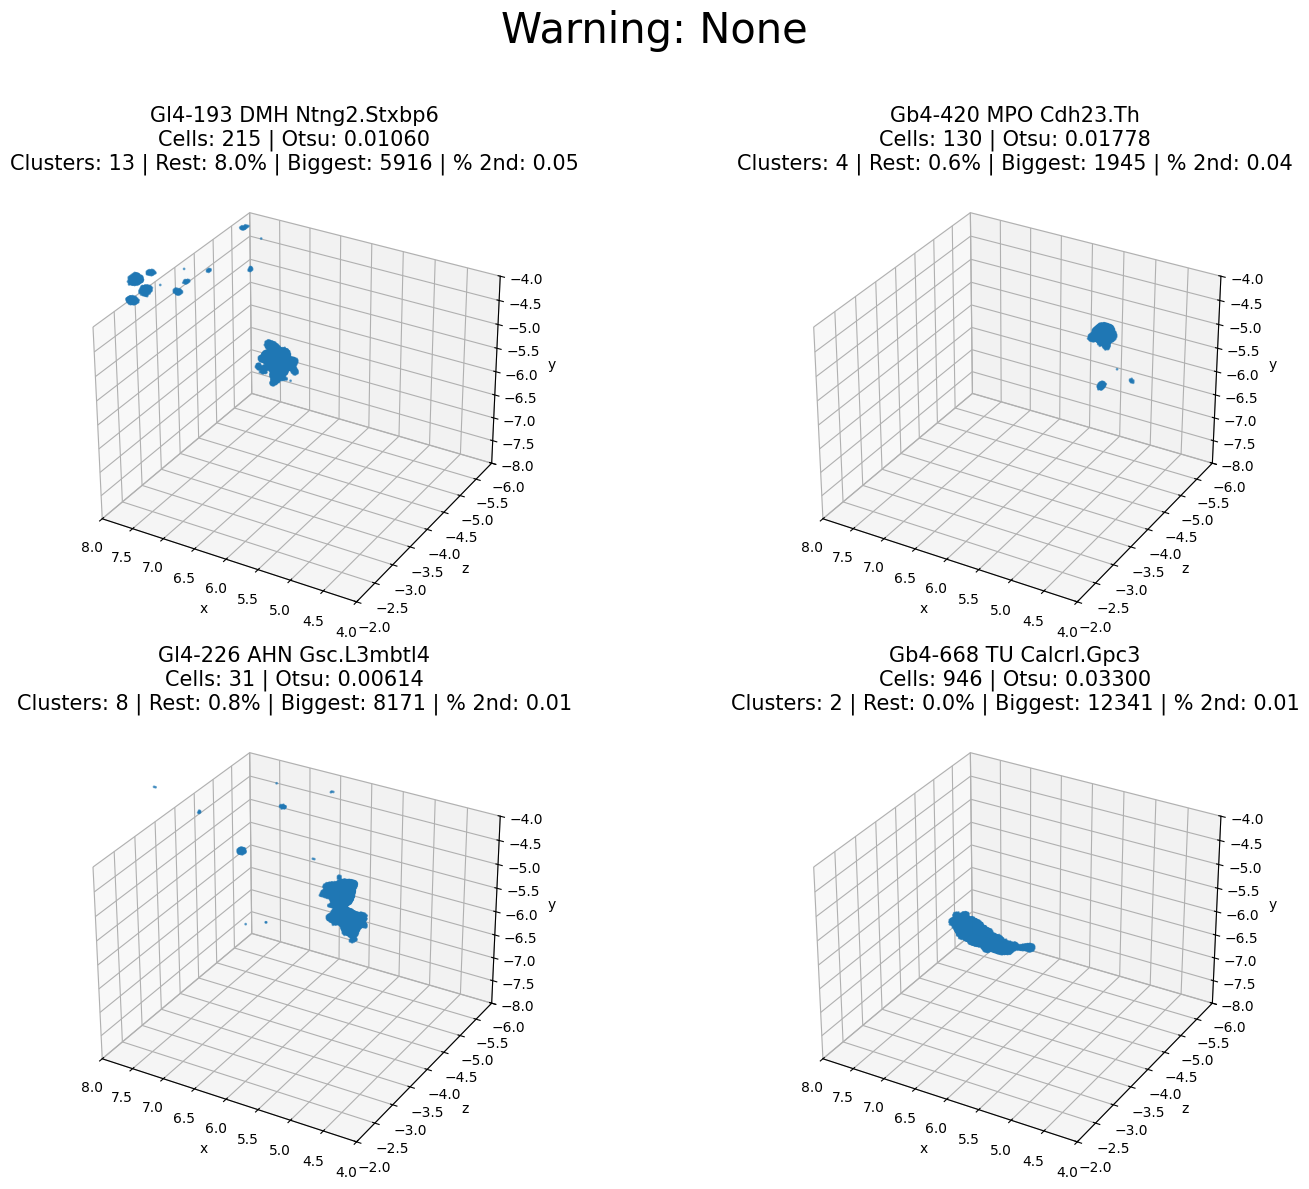

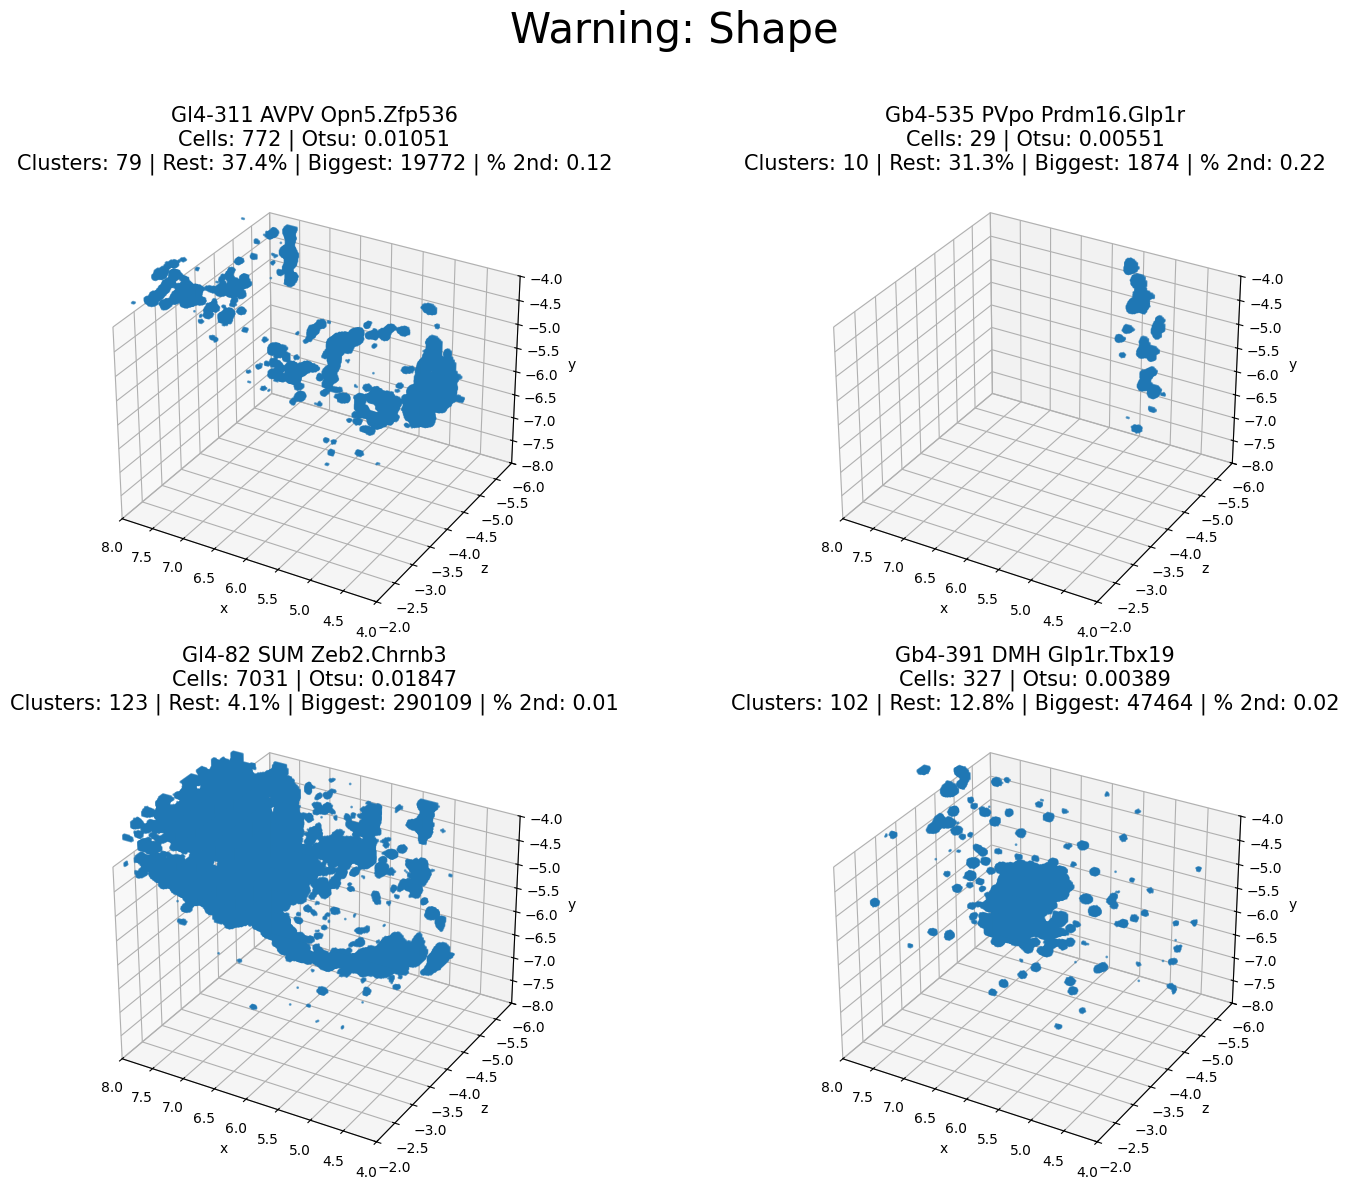

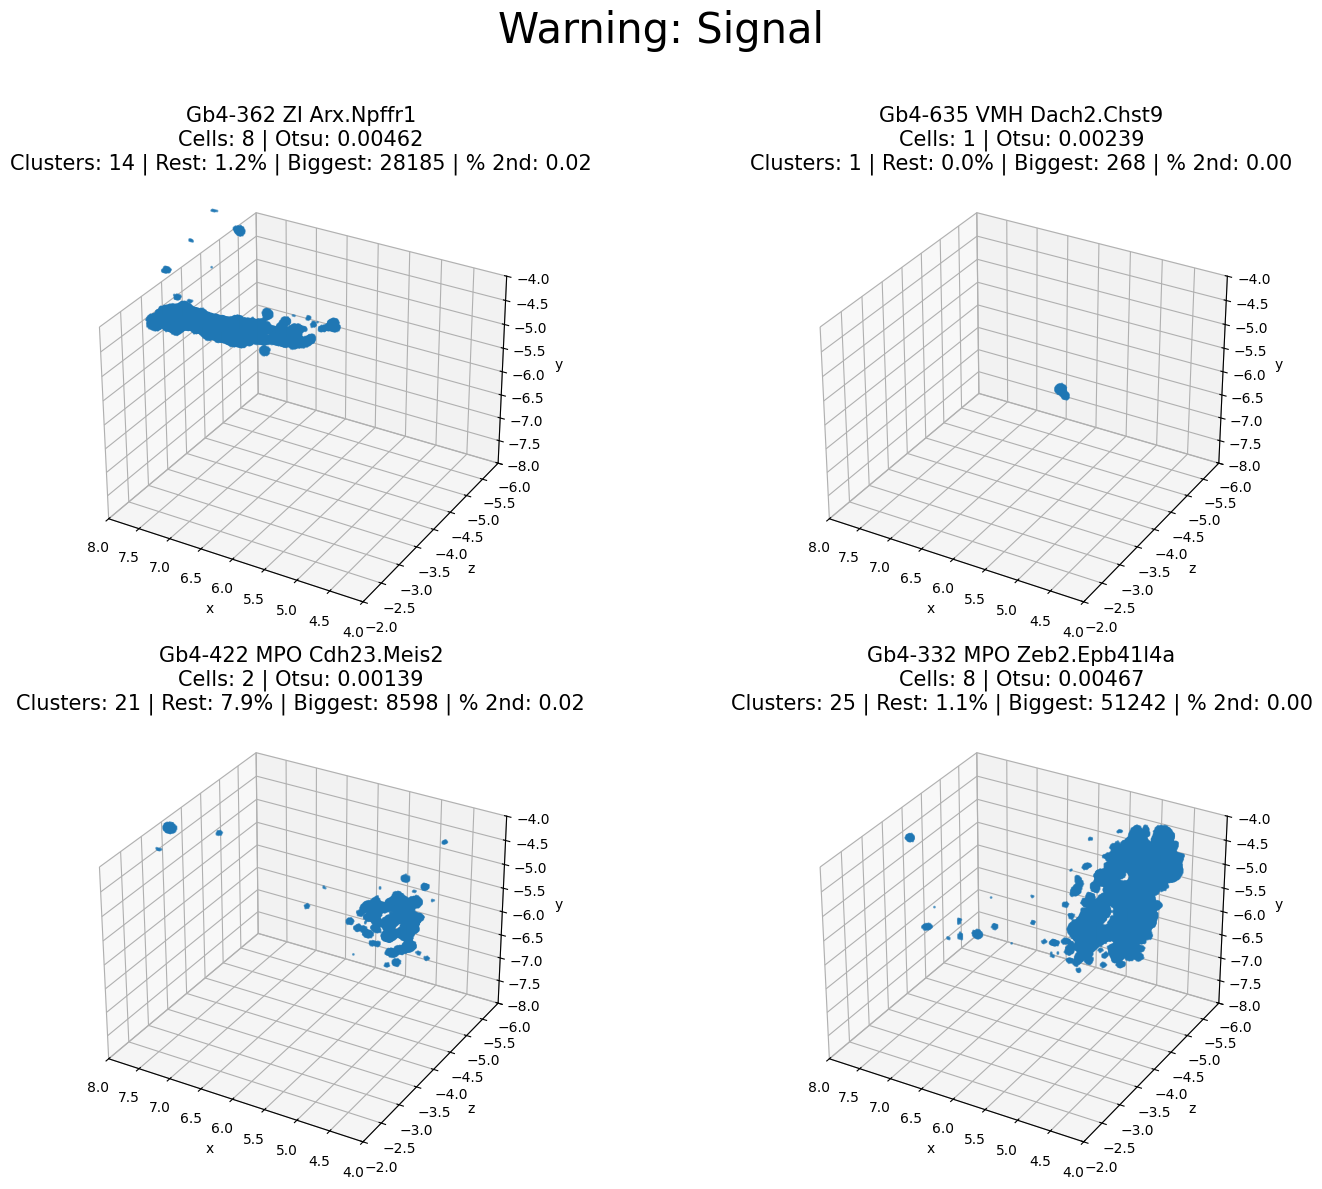

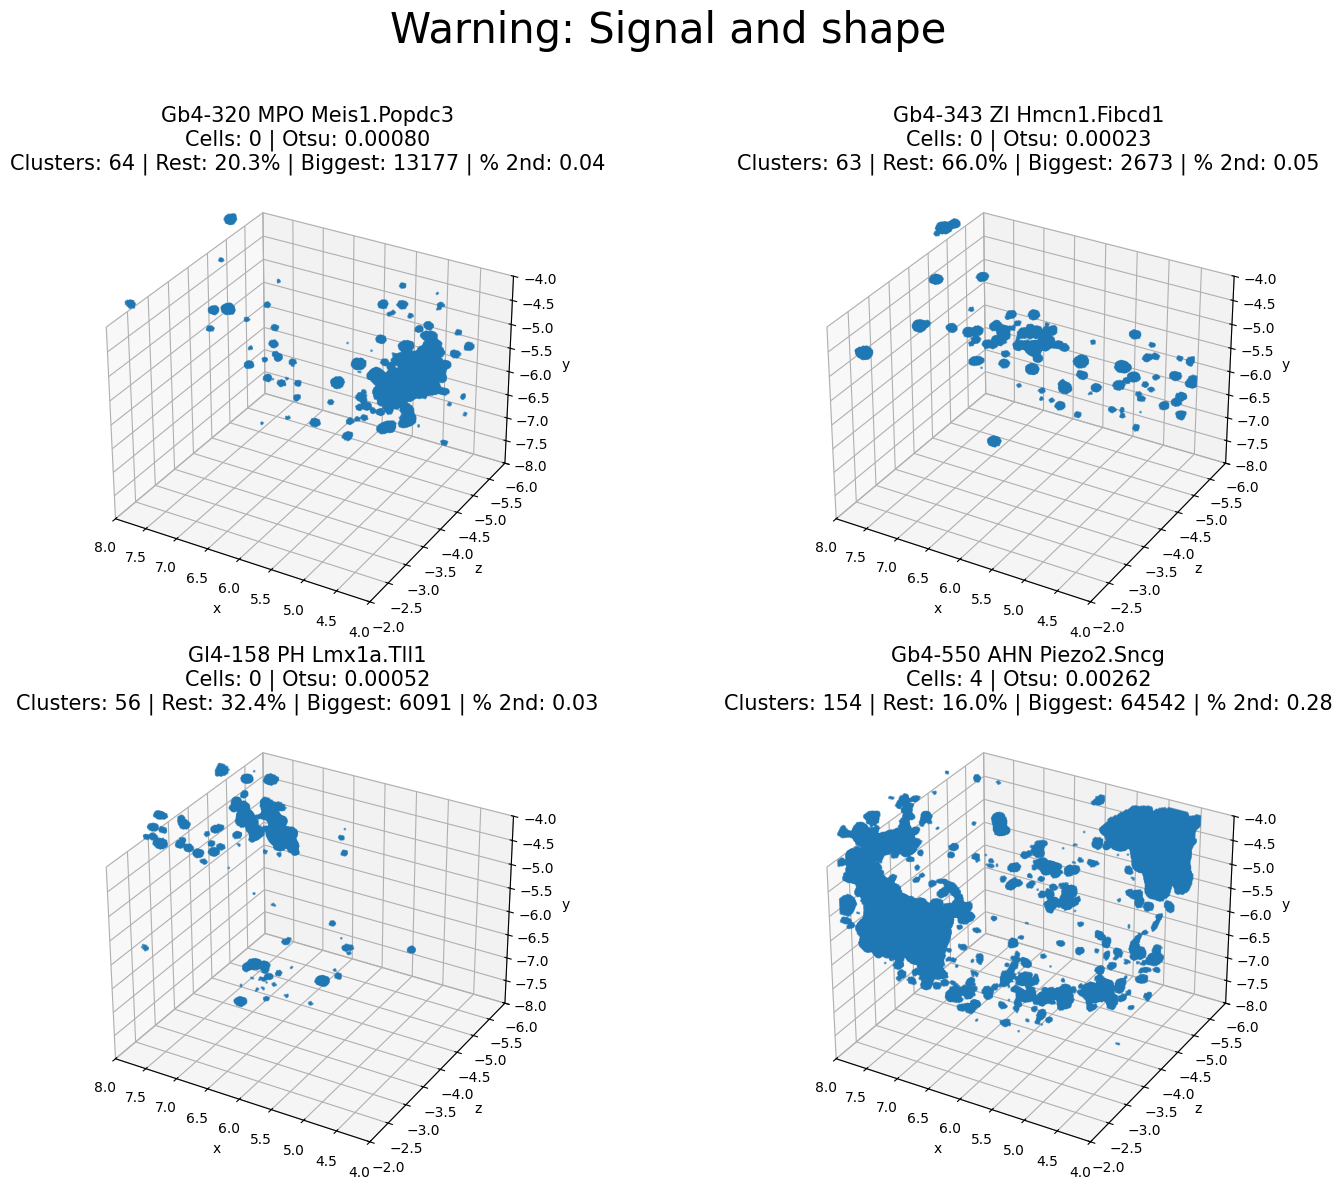

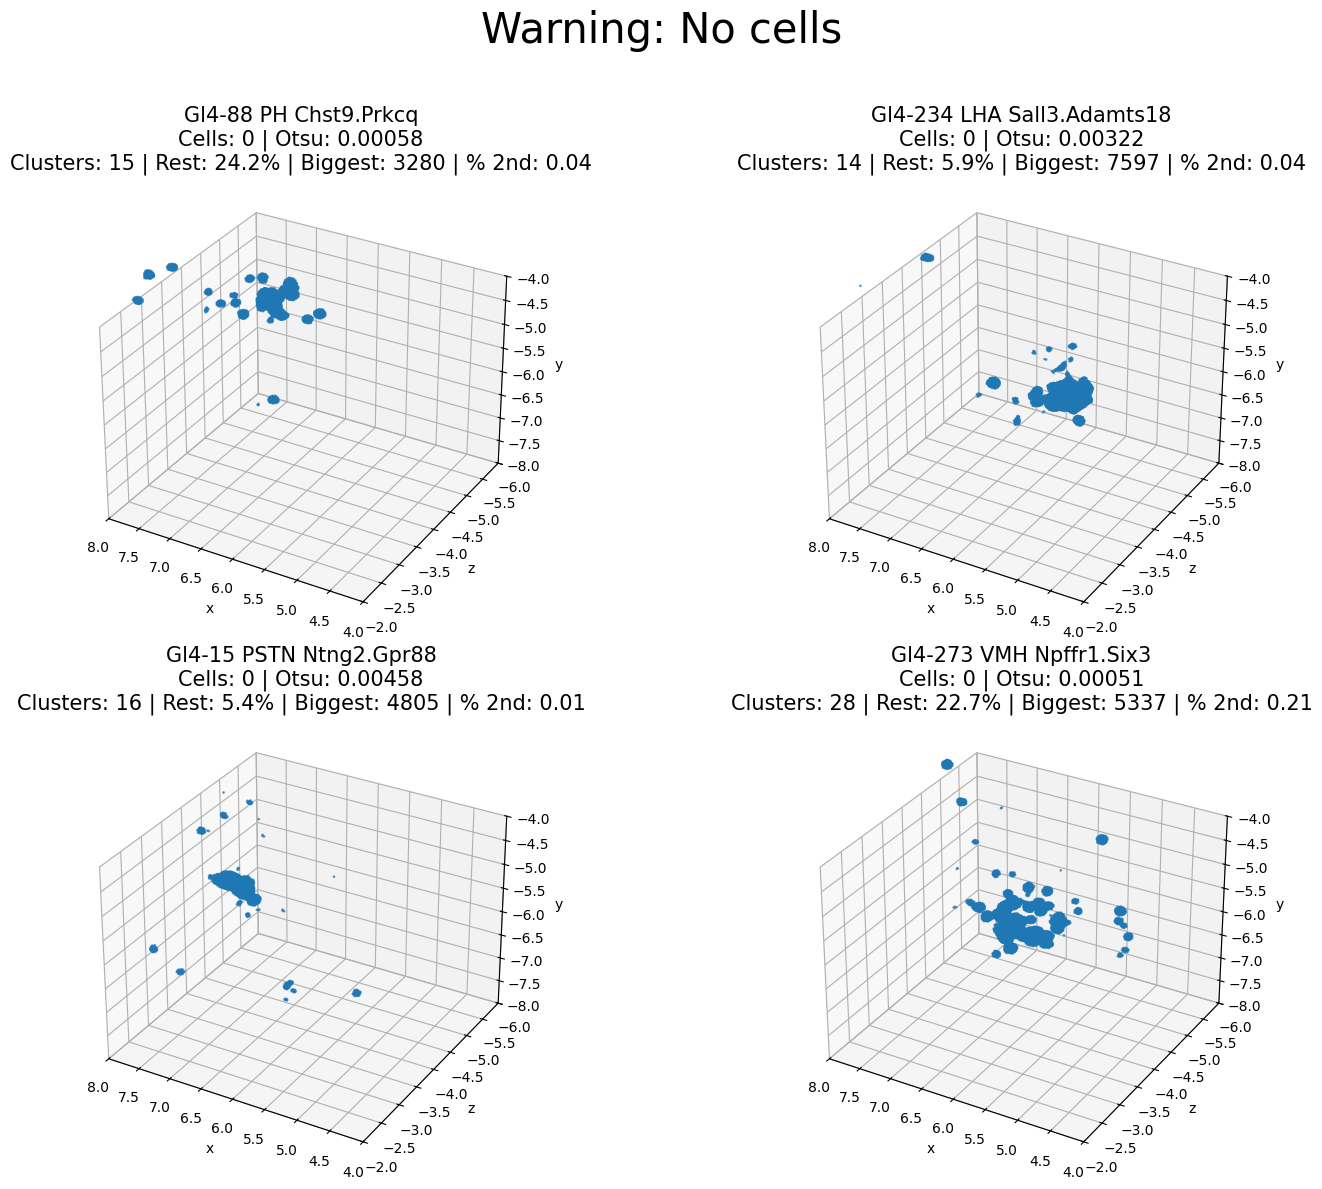

In [ ]:
lvl= "L4"

plot_random_clusters_by_warning_qc_3d(
    joined=joined,
    level=lvl,
    is_NN=False,
    n=4,
    random_state=42,
    use_frontleft = True,
    single_plots=False
)

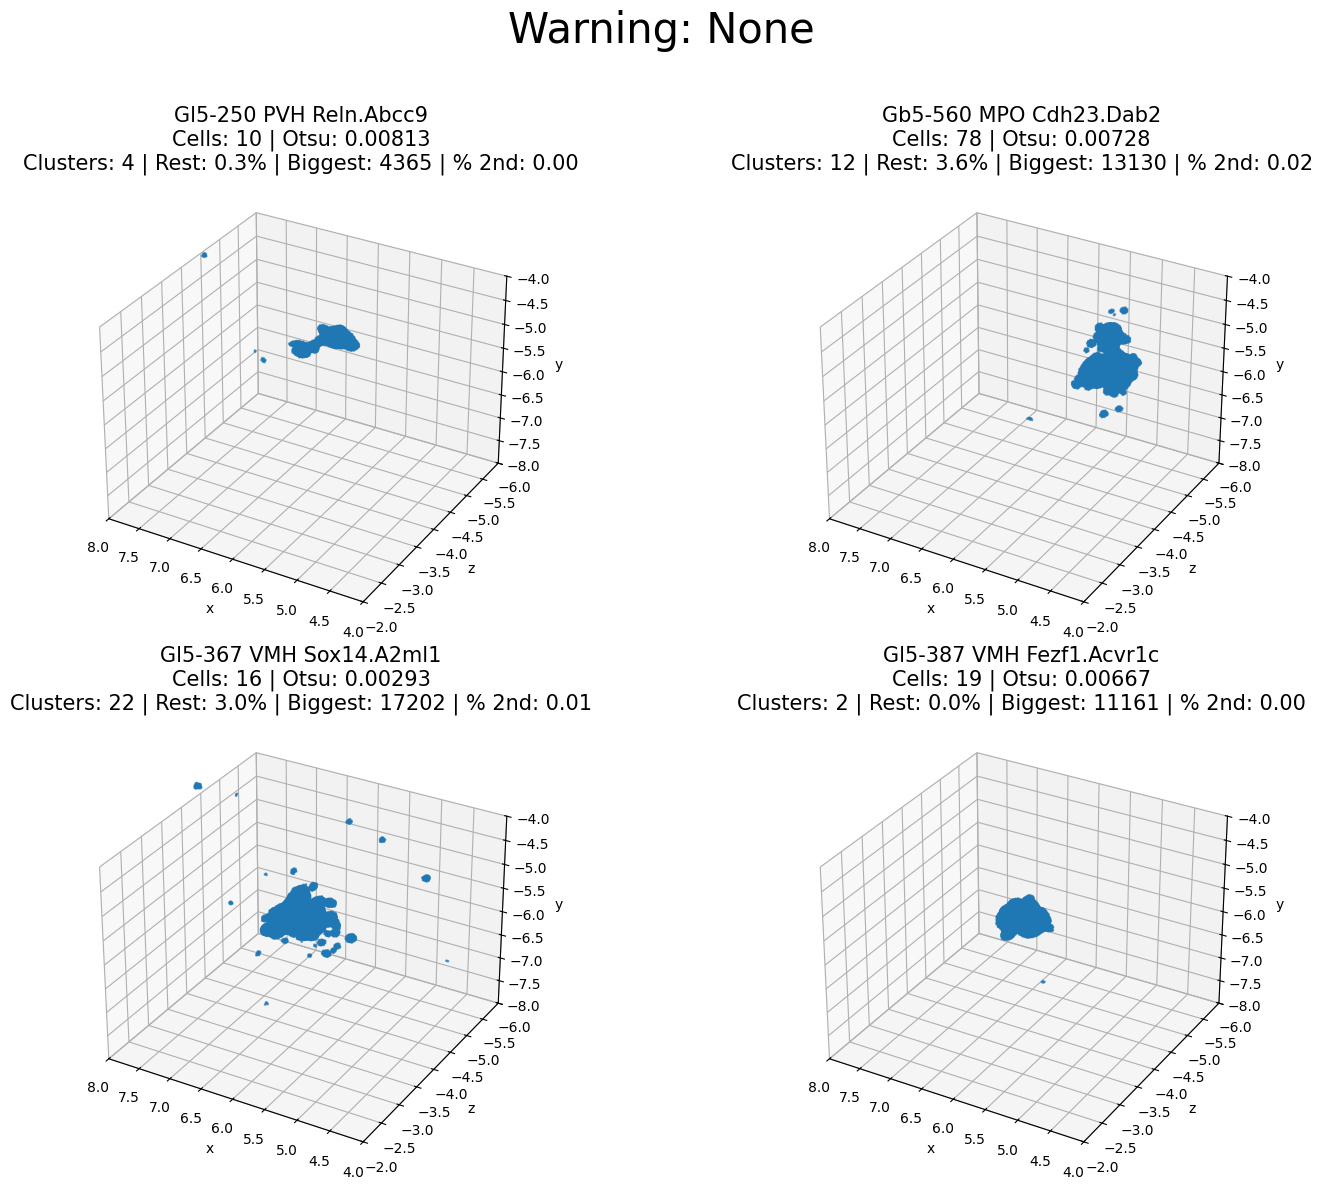

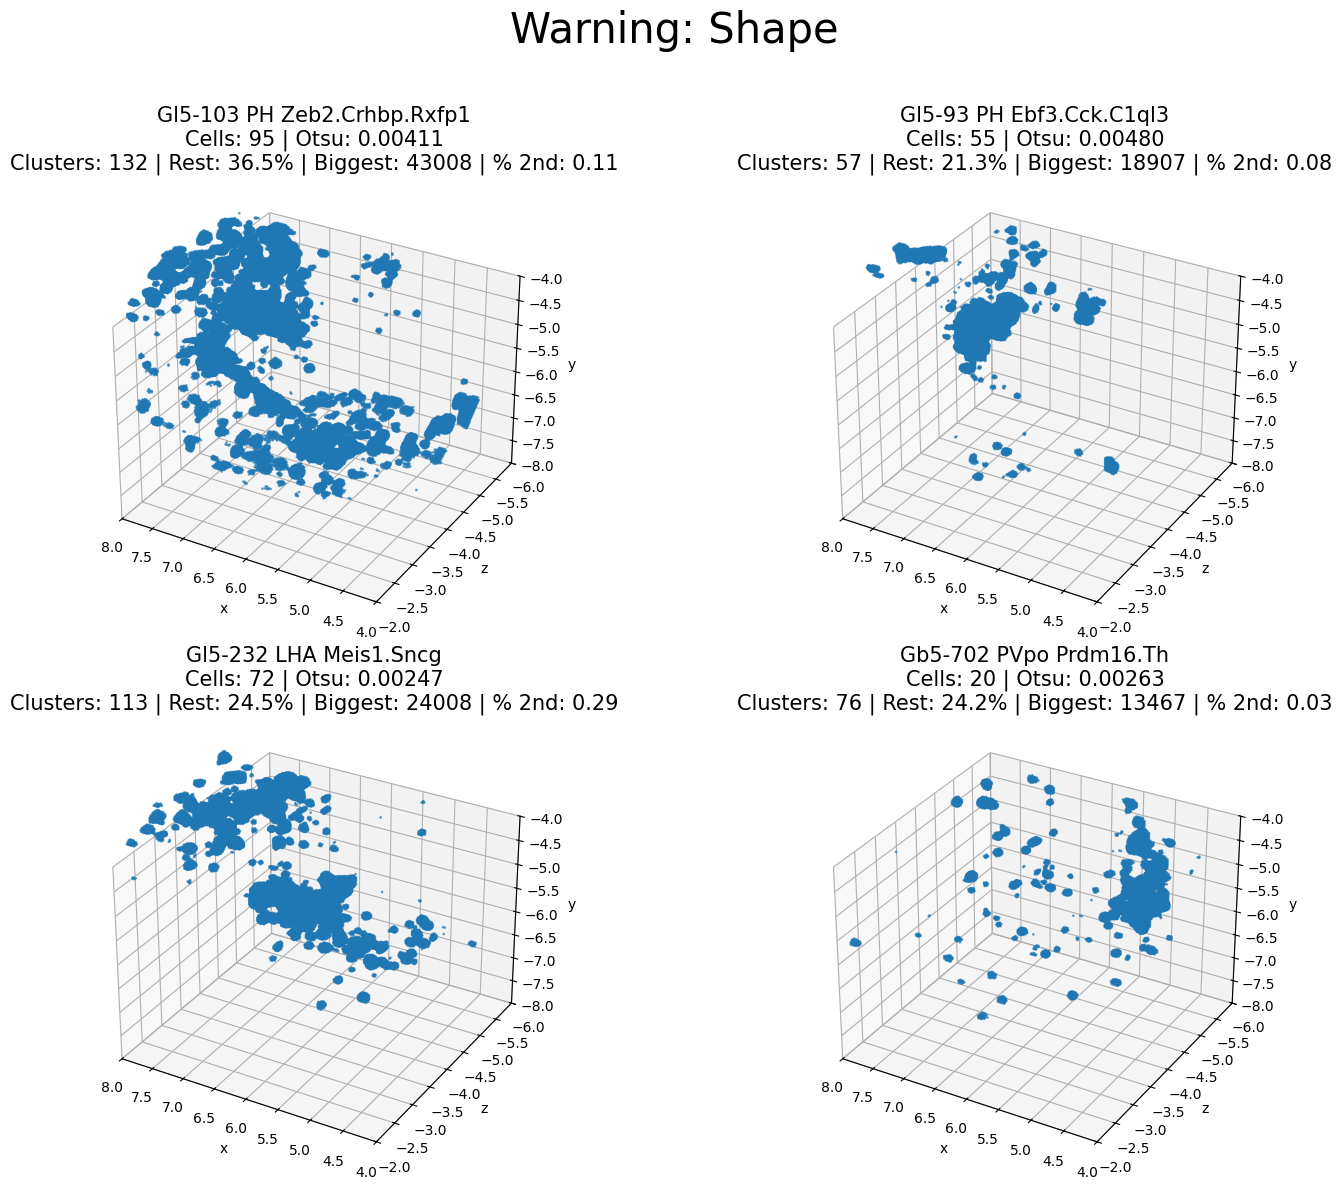

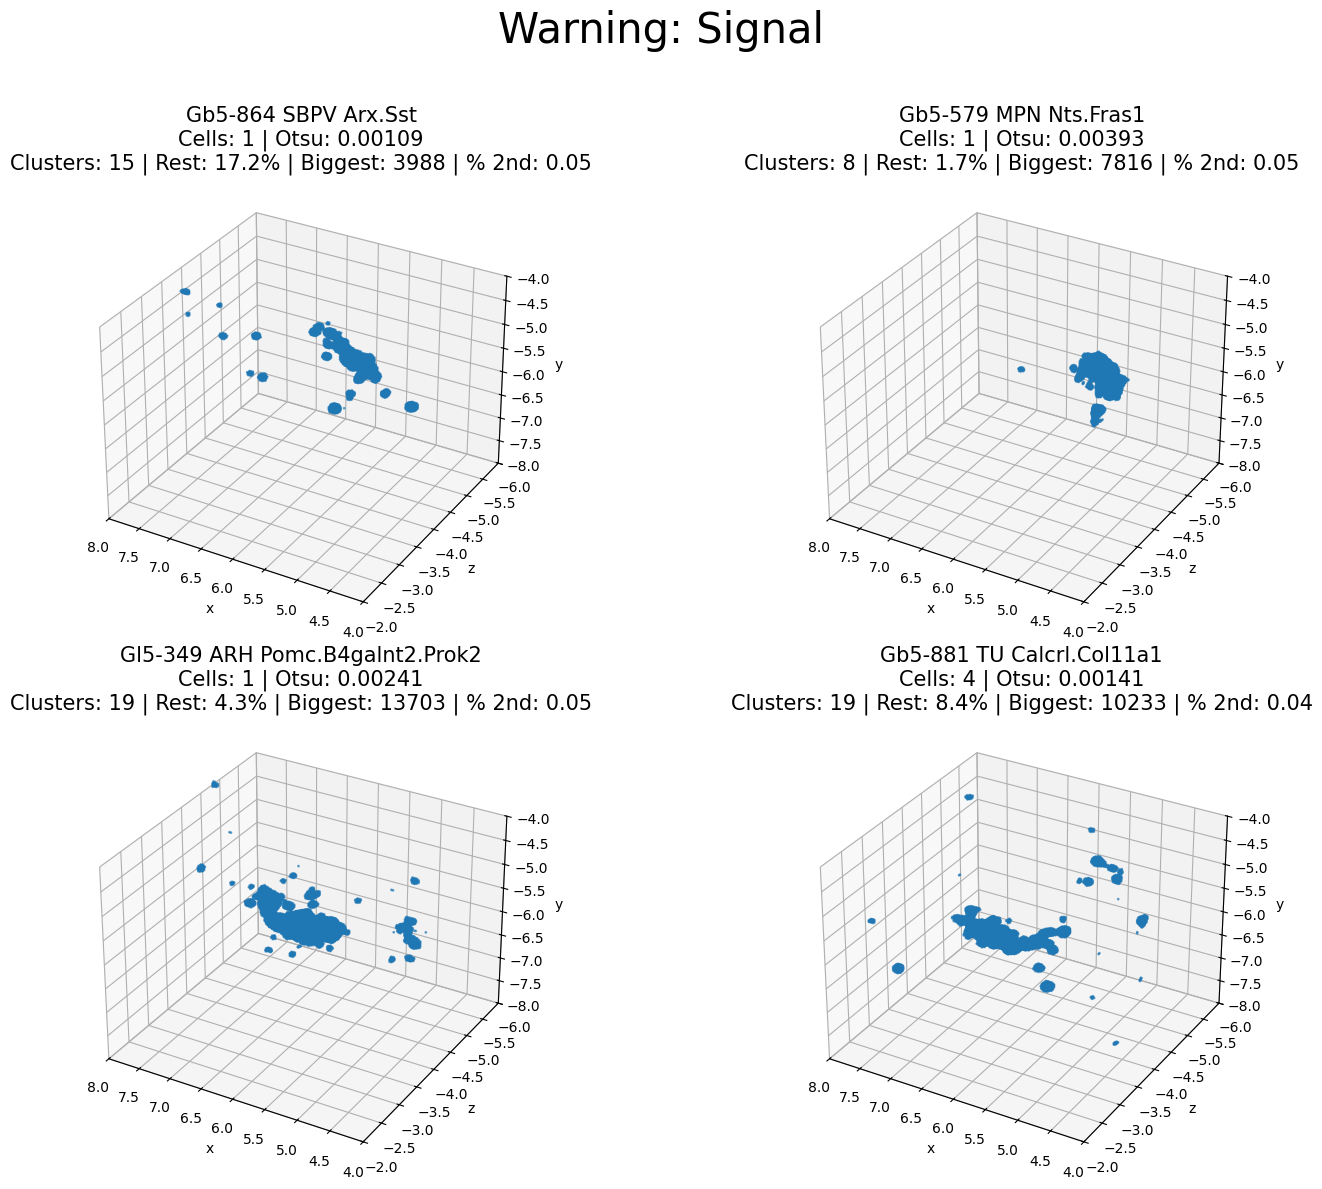

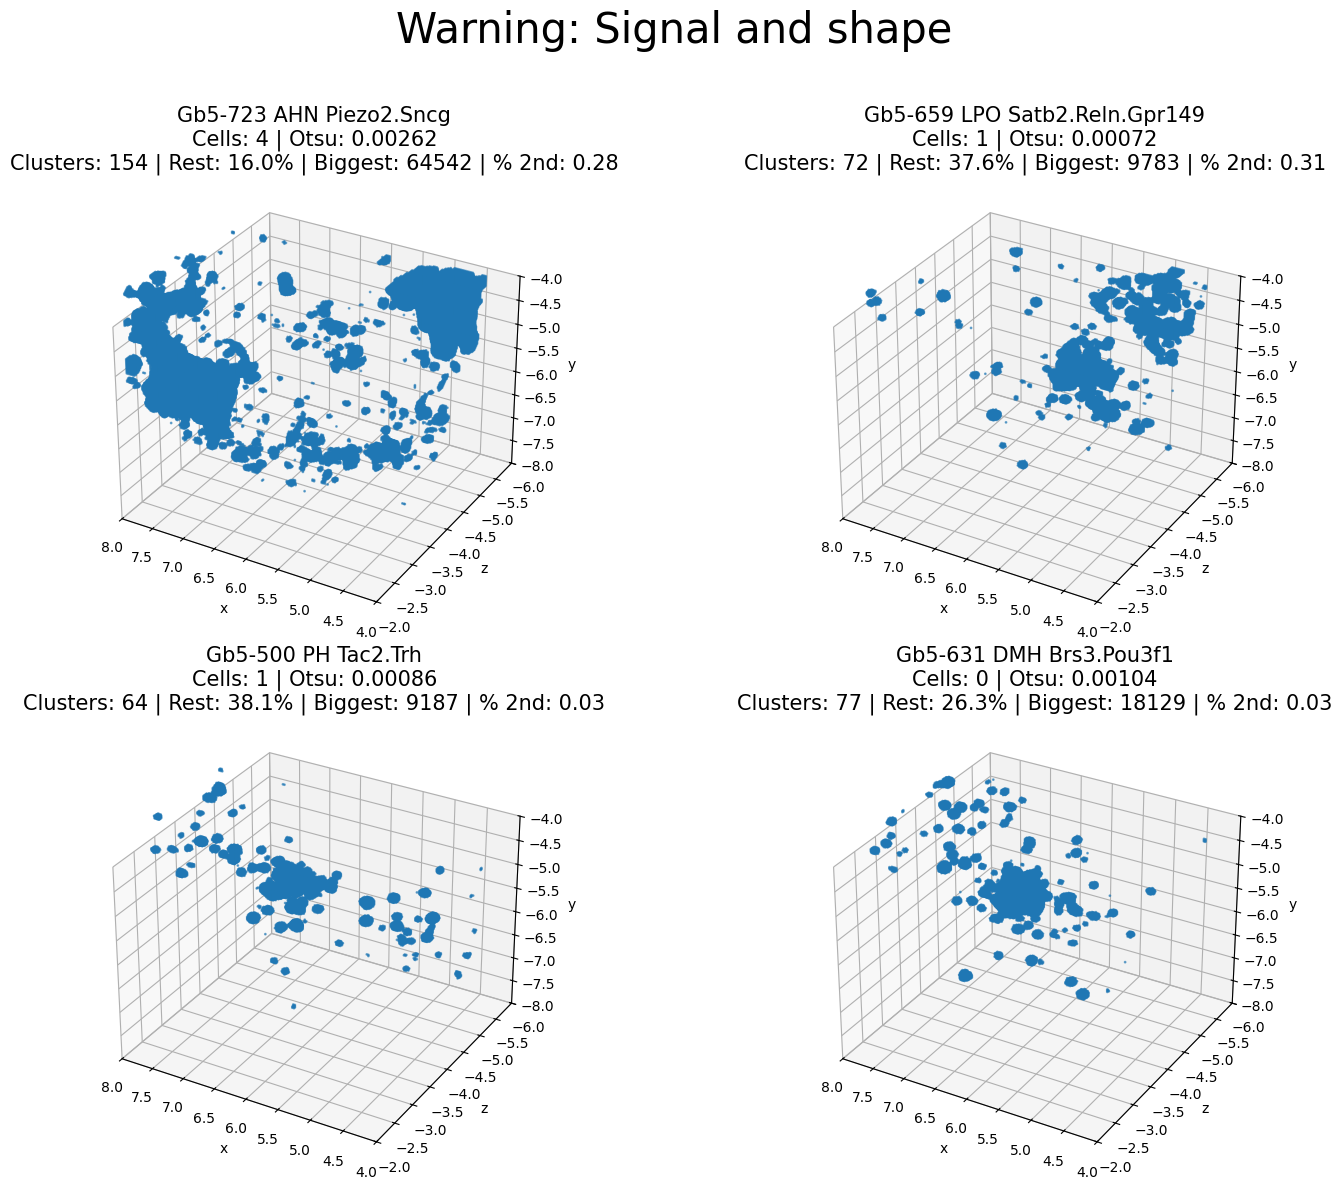

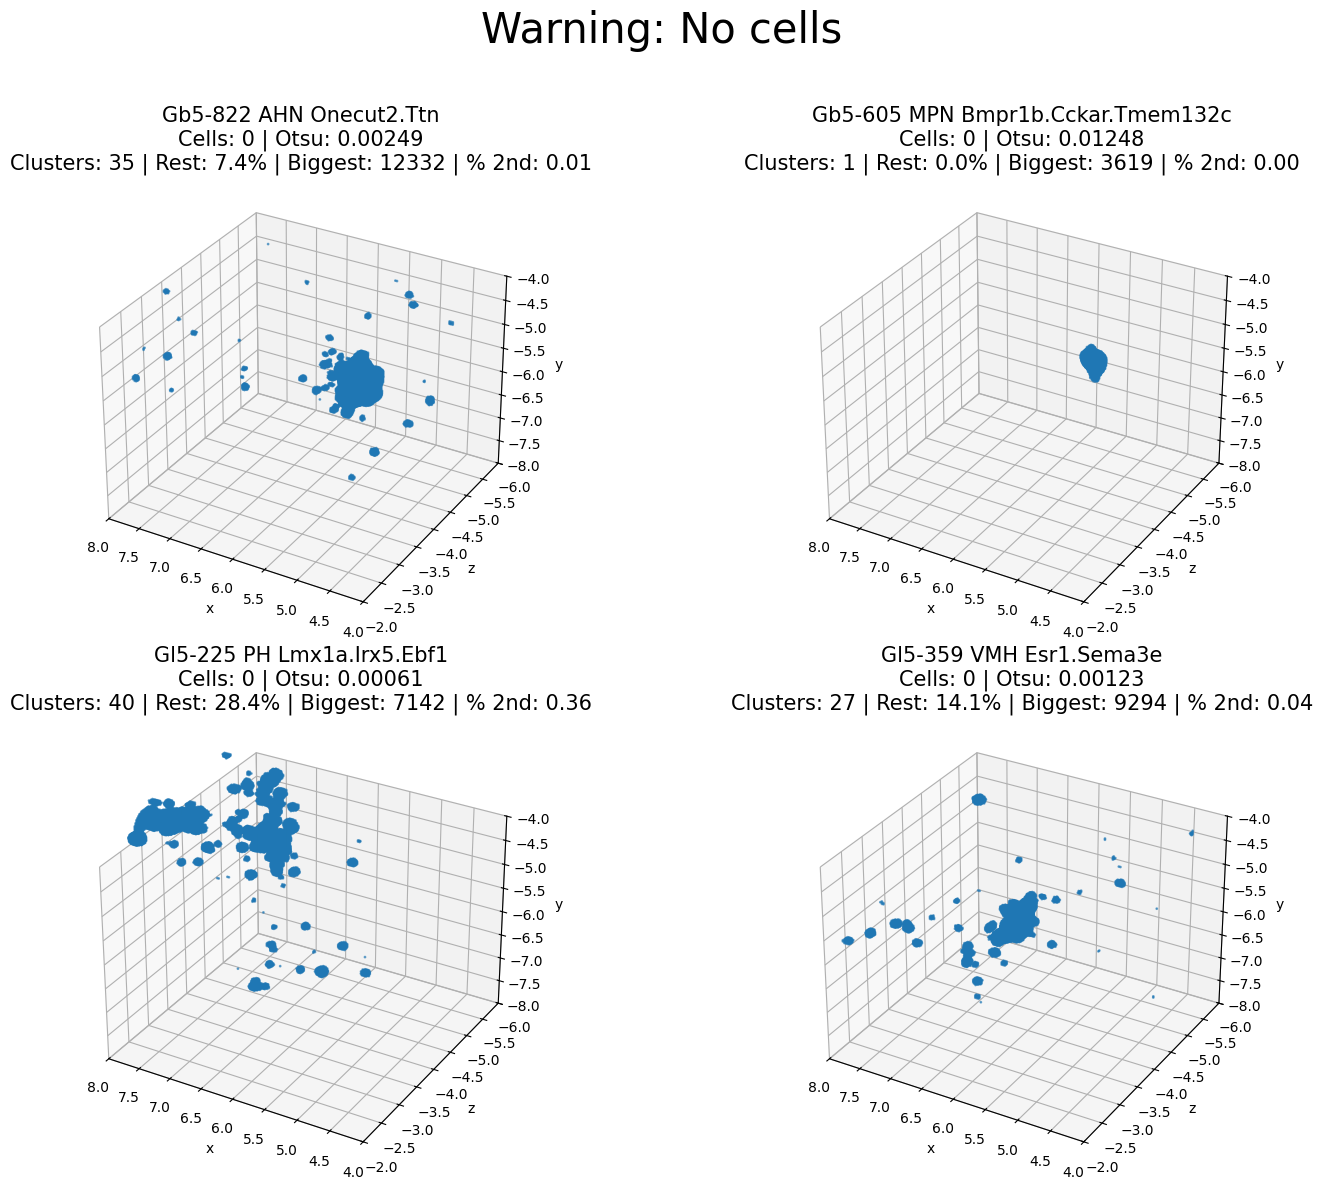

In [93]:
lvl= "L5"

plot_random_clusters_by_warning_qc_3d(
    #aas=aas,
    joined=joined,
    level=lvl,
    is_NN=False,
    n=4,
    random_state=42,
    use_frontleft = True,
    single_plots=False
)